# HyperSpot Human Kidney Cancer Interface Data Preparation

## Contents
1. [Data Preparation: Loading and Processing](#Load-data)


In [1]:
import os
import matplotlib as mpl
import scanpy as sc

from pathlib import Path
from hyperspot.preprocessing import common, image, kidneycancer

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

Specify the input folder.

In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')
patient_id = 'PD47171'

Specify the output folder.

In [3]:
spotiphy_proj_folder = Path("spotiphy_project_files/Human Kidney Cancer Interface/")
spotiphy_proj_folder.mkdir(parents=True, exist_ok=True)    

## Data Preparation: Loading and Processing <a id=Load-data></a>

Load the scRNA data and visium data.

In [4]:
adata_sc = sc.read_h5ad(data_dir / "RCC_upload_final_raw_counts.h5ad")
adata_st_inter = sc.read_h5ad(data_dir / "visium_merge_inter_upload.h5ad")

Extract the speciment of interest (patient PD47171) from the scRNA and visium data.

In [5]:
# Extract data of patient PD47171
adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)
adata_st_inter = kidneycancer.extract_st_patient_data(adata_st_inter, patient_id)

Format scRNA data to use ENSEMBLE gene ids as index to align it with the visium data.

In [6]:
adata_sc, adata_st_inter

(AnnData object with n_obs × n_vars = 36110 × 19736
     obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
     var: 'name'
     uns: 'annotation_colors', 'broad_type_colors', 'region_colors', 'summaryDescription_colors'
     obsm: 'X_pca', 'X_umap',
 AnnData object with n_obs × n_vars = 2048 × 36601
     obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
     var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411'
     uns: 'sample_colors', 'spatial'
    

In [7]:
out = (
    adata_sc.obs
        .groupby(['broad_type', 'annotation'])
        .size()
        .reset_index(name='count')
        .loc[lambda r: r['count'] > 0]
)
out

/tmp/ipykernel_418083/2289168175.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['broad_type', 'annotation'])


,broad_type,annotation,count
3,B-cell,Activated_B-AREG,41
4,B-cell,Activated_B-RHOB,32
47,B-cell,INF-response_B,15
62,B-cell,Naïve_B.1,298
64,B-cell,Non-switched-memory_B,65
...,...,...,...
961,T-cell,NK-IFNG-high,1
986,T-cell,cir_NK-S100B,2
987,T-cell,gdT_Vd1,69
988,T-cell,gdT_Vd2,91


In [8]:
# possible archives:
# feb2021.archive.ensembl.org - currently not available
geneset = common.get_annotation(
    host="dec2021.archive.ensembl.org", 
    cache_filename="GRCh38-2020-A_annotations.json"
)

Loaded annotation for 'dec2021.archive.ensembl.org' from cache.


In [9]:
conflicts = kidneycancer.find_conflicting_genes(adata_sc, adata_st_inter, geneset)
conflicts

                  SYMBOL
ENSEMBL                 
ENSG00000285053     TBCE
ENSG00000284770     TBCE
ENSG00000280987    MATR3
ENSG00000015479    MATR3
ENSG00000284024   HSPA14
ENSG00000187522   HSPA14
ENSG00000286070     GGT1
ENSG00000100031     GGT1
ENSG00000158427  TMSB15B
ENSG00000269226  TMSB15B
Found 5 symbols with duplicate Ensembl IDs
  → 5 overlap with scRNA-seq and require manual inspection
  → 0 are absent from scRNA-seq and will be handled automatically



,SYMBOL,total_counts,pct_nonzero,would_keep,in_sc
ENSEMBL,,,,,
ENSG00000100031,GGT1,11.0,0.004883,True,True
ENSG00000286070,GGT1,3.0,0.001465,False,True
ENSG00000187522,HSPA14,225.0,0.095215,True,True
ENSG00000284024,HSPA14,176.0,0.080078,False,True
ENSG00000015479,MATR3,10.0,0.004883,True,True
ENSG00000280987,MATR3,0.0,0.000000,False,True
ENSG00000284770,TBCE,54.0,0.025391,True,True
ENSG00000285053,TBCE,2.0,0.000977,False,True
ENSG00000269226,TMSB15B,24.0,0.011719,True,True


In [10]:
drop_cols = [
    'ENSG00000286070',  # GGT1
    'ENSG00000280987',  # MATR3
    'ENSG00000285053',  # TBCE
]

rename_cols = {
    'ENSG00000284024': 'MSANTD7',
    'ENSG00000269226': 'TMSB15C'
}

In [11]:
# TODO
# TMSB15B -> rename ENSG00000269226 to TMSB15C
# MATR3 -> drop ENS00000280987
# TBCE -> drop ENSG00000285053
adata_sc, adata_st_inter = kidneycancer.use_ensembl_gene_ids(
    adata_sc, 
    adata_st_inter,
    geneset,
    drop_cols = drop_cols, 
    rename_cols = rename_cols
)

Retained 15222 genes common to both datasets
  scRNA-seq: 19736 → 15222 genes
  Spatial:   36601 → 15222 genes


In [12]:
adata_sc.X.max(), adata_sc.X.mean()

(np.float32(825.0), np.float32(0.19616425))

Extract the corresponding H&E staining image from the visium data

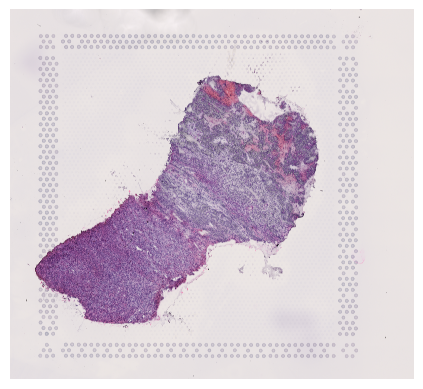

In [13]:
# Get ST image
img = image.get_image(adata_st_inter, scale=True)

# Plot without axes
mpl.pyplot.imshow(img)
mpl.pyplot.axis('off')  # Remove axis ticks and labels
mpl.pyplot.show()

Save the files prepared scRNA data, visium data, and image separately. These will be the inputs to Spotiphy.

In [14]:
adata_sc.write(spotiphy_proj_folder / 'Human Kidney Cancer scRNA Ref.h5ad')
adata_st_inter.write(spotiphy_proj_folder / 'Human Kidney Cancer Interface.h5ad')
img.save(spotiphy_proj_folder / 'Human Kidney Cancer Interface.tif')

In [15]:
interest_genes = ['NDRG1', 'RPL13', 'TMEM45A']


In [16]:
geneset

,external_gene_name,gene_biotype,chromosome_name
ENSG00000198888,MT-ND1,protein_coding,MT
ENSG00000198763,MT-ND2,protein_coding,MT
ENSG00000198804,MT-CO1,protein_coding,MT
ENSG00000198712,MT-CO2,protein_coding,MT
ENSG00000228253,MT-ATP8,protein_coding,MT
...,...,...,...
ENSG00000142961,MOB3C,protein_coding,1
ENSG00000116754,SRSF11,protein_coding,1
ENSG00000283324,CTXND2,protein_coding,1
ENSG00000077585,GPR137B,protein_coding,1


In [17]:
interest_gene_ensembl = geneset[geneset['external_gene_name'].isin(interest_genes)].index

In [18]:
interest_gene_ensembl

Index(['ENSG00000104419', 'ENSG00000167526', 'ENSG00000181458'], dtype='object')

In [19]:
adata_sc = sc.read_h5ad(spotiphy_proj_folder / 'Human Kidney Cancer scRNA Ref.h5ad')
adata_st_inter = sc.read_h5ad(spotiphy_proj_folder / 'Human Kidney Cancer Interface.h5ad')

In [20]:
adata_st_inter.var[adata_st_inter.var_names.isin(interest_gene_ensembl)]

,feature_types,genome,SYMBOL,mt,n_cells_by_counts-6800STDY12499411,mean_counts-6800STDY12499411,log1p_mean_counts-6800STDY12499411,pct_dropout_by_counts-6800STDY12499411,total_counts-6800STDY12499411,log1p_total_counts-6800STDY12499411
ENSEMBL,,,,,,,,,,
ENSG00000181458,Gene Expression,GRCh38,TMEM45A,False,473,0.317383,0.275647,76.904297,650.0,6.478509
ENSG00000104419,Gene Expression,GRCh38,NDRG1,False,1528,4.693848,1.739386,25.390625,9613.0,9.170976
ENSG00000167526,Gene Expression,GRCh38,RPL13,False,2047,34.459961,3.568404,0.048828,70574.0,11.164432


In [21]:
adata_sc

AnnData object with n_obs × n_vars = 36110 × 15222
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
    var: 'name'
    uns: 'annotation_colors', 'broad_type_colors', 'region_colors', 'summaryDescription_colors'
    obsm: 'X_pca', 'X_umap'

In [22]:
adata_st_inter

AnnData object with n_obs × n_vars = 2048 × 15222
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'

In [23]:
adata_sc.var[adata_sc.var['name'].isin(interest_genes)]

,name
ENSEMBL,
ENSG00000181458,TMEM45A
ENSG00000104419,NDRG1
ENSG00000167526,RPL13


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:916: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.set_title(fig_params.title[count])


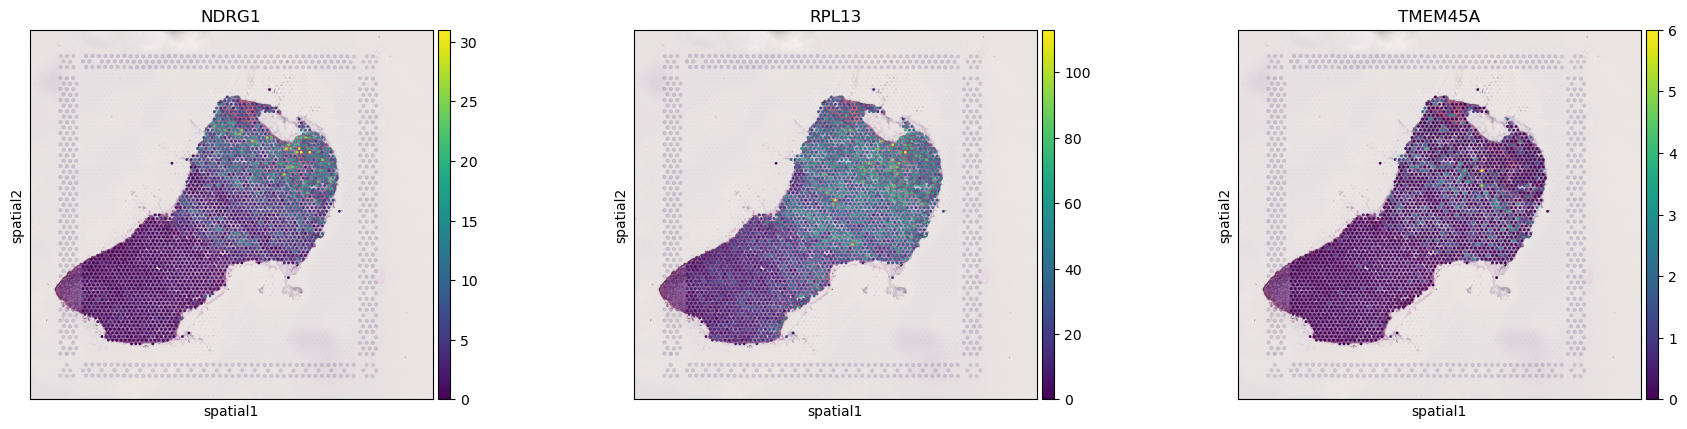

In [24]:
import squidpy as sq
sq.pl.spatial_scatter(adata_st_inter, color = interest_gene_ensembl, title=geneset.loc[interest_gene_ensembl].external_gene_name)

In [25]:
adata_sc

AnnData object with n_obs × n_vars = 36110 × 15222
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
    var: 'name'
    uns: 'annotation_colors', 'broad_type_colors', 'region_colors', 'summaryDescription_colors'
    obsm: 'X_pca', 'X_umap'